In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as layers

In [2]:
df = pd.read_csv("data\mnist_train.csv")
df.head(20)

C:\Users\aahan\AppData\Local\Temp\ipykernel_1088\115029169.py:1: DtypeWarning: Columns (0: label, 1: pixel1, 2: pixel2, 3: pixel3, 4: pixel4, 5: pixel5, 6: pixel6, 7: pixel7, 8: pixel8, 9: pixel9, 10: pixel10, 11: pixel11, 12: pixel12, 13: pixel13, 14: pixel14, 15: pixel15, 16: pixel16, 17: pixel17, 18: pixel18, 19: pixel19, 20: pixel20, 21: pixel21, 22: pixel22, 23: pixel23, 24: pixel24, 25: pixel25, 26: pixel26, 27: pixel27, 28: pixel28, 29: pixel29, 30: pixel30, 31: pixel31, 32: pixel32, 33: pixel33, 34: pixel34, 35: pixel35, 36: pixel36, 37: pixel37, 38: pixel38, 39: pixel39, 40: pixel40, 41: pixel41, 42: pixel42, 43: pixel43, 44: pixel44, 45: pixel45, 46: pixel46, 47: pixel47, 48: pixel48, 49: pixel49, 50: pixel50, 51: pixel51, 52: pixel52, 53: pixel53, 54: pixel54, 55: pixel55, 56: pixel56, 57: pixel57, 58: pixel58, 59: pixel59, 60: pixel60, 61: pixel61, 62: pixel62, 63: pixel63, 64: pixel64, 65: pixel65, 66: pixel66, 67: pixel67, 68: pixel68, 69: pixel69, 70: pixel70, 71: pixel7

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
1,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
df = df.drop(0)

In [4]:
df.head(5)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
1,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
y_train = df["label"]
y_train = df["label"].astype("int32")
X_train = df.drop("label", axis=1)
X_train = X_train.apply(pd.to_numeric)
X_train = X_train / 255.0

In [6]:
print(X_train.dtypes.unique())
print(y_train.dtype)
print(X_train.info())

[dtype('float64')]
int32
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 1 to 60000
Columns: 784 entries, pixel1 to pixel784
dtypes: float64(784)
memory usage: 358.9 MB
None


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input,Dropout
from tensorflow.keras.optimizers import Adam

In [12]:
model = Sequential([
    Dense(128,activation='relu',input_shape=(784,)),
    Dropout(0.2),
    Dense(64,activation='relu'),
    Dropout(0.2),
    Dense(10,activation='softmax')
])

In [19]:
opti = Adam(learning_rate=0.0005)
model.compile(
    optimizer = opti,
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [20]:
model.fit(
    X_train,
    y_train,
    epochs = 20,
    validation_split = 0.15
)

Epoch 1/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9898 - loss: 0.0302 - val_accuracy: 0.9860 - val_loss: 0.0588
Epoch 2/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9912 - loss: 0.0273 - val_accuracy: 0.9873 - val_loss: 0.0611
Epoch 3/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9912 - loss: 0.0276 - val_accuracy: 0.9888 - val_loss: 0.0570
Epoch 4/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9915 - loss: 0.0255 - val_accuracy: 0.9884 - val_loss: 0.0567
Epoch 5/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9920 - loss: 0.0236 - val_accuracy: 0.9880 - val_loss: 0.0547
Epoch 6/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9924 - loss: 0.0238 - val_accuracy: 0.9871 - val_loss: 0.0552
Epoch 7/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9926 - loss: 0.0234 - val_accuracy: 0.9868 - val_loss: 0.0550
Epoch 8/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9933 - loss: 0.0217 - 

In [21]:
testing_dataset = pd.read_csv('data\mnist_test.csv')
testing_dataset = testing_dataset.iloc[1:].reset_index(drop=True)
y_test = testing_dataset["label"].astype("int32")
x_test = testing_dataset.drop("label", axis=1).astype("float32") / 255.0
# y_train = y_train.to_numpy(dtype=np.int32)
y_train = y_train.astype(np.int32) 
y_test = np.asarray(y_test, dtype=np.int32)

X_train = np.asarray(X_train, dtype=np.float32)
x_test = np.asarray(x_test, dtype=np.float32)

C:\Users\aahan\AppData\Local\Temp\ipykernel_1088\3272654747.py:1: DtypeWarning: Columns (0: label, 1: pixel1, 2: pixel2, 3: pixel3, 4: pixel4, 5: pixel5, 6: pixel6, 7: pixel7, 8: pixel8, 9: pixel9, 10: pixel10, 11: pixel11, 12: pixel12, 13: pixel13, 14: pixel14, 15: pixel15, 16: pixel16, 17: pixel17, 18: pixel18, 19: pixel19, 20: pixel20, 21: pixel21, 22: pixel22, 23: pixel23, 24: pixel24, 25: pixel25, 26: pixel26, 27: pixel27, 28: pixel28, 29: pixel29, 30: pixel30, 31: pixel31, 32: pixel32, 33: pixel33, 34: pixel34, 35: pixel35, 36: pixel36, 37: pixel37, 38: pixel38, 39: pixel39, 40: pixel40, 41: pixel41, 42: pixel42, 43: pixel43, 44: pixel44, 45: pixel45, 46: pixel46, 47: pixel47, 48: pixel48, 49: pixel49, 50: pixel50, 51: pixel51, 52: pixel52, 53: pixel53, 54: pixel54, 55: pixel55, 56: pixel56, 57: pixel57, 58: pixel58, 59: pixel59, 60: pixel60, 61: pixel61, 62: pixel62, 63: pixel63, 64: pixel64, 65: pixel65, 66: pixel66, 67: pixel67, 68: pixel68, 69: pixel69, 70: pixel70, 71: pixel

In [22]:
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)
accuracy = np.mean(predicted_labels == y_test)
print(f"Test Accuracy: {accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Test Accuracy: 0.9808


Number wrong: 192


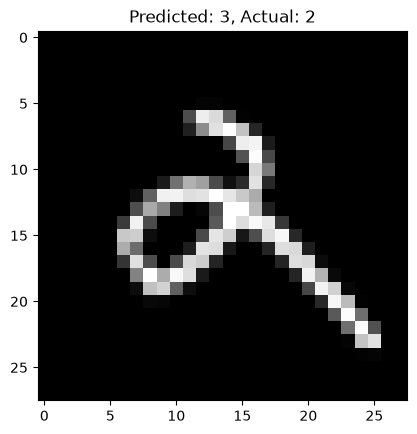

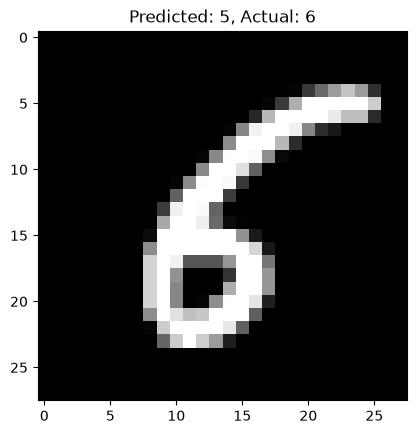

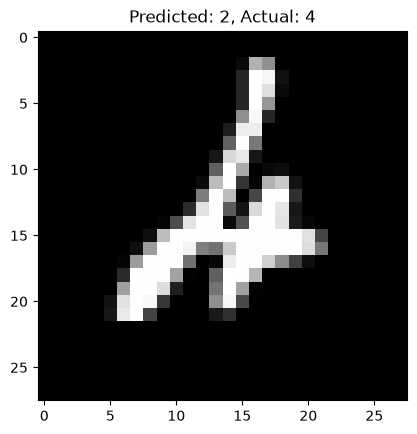

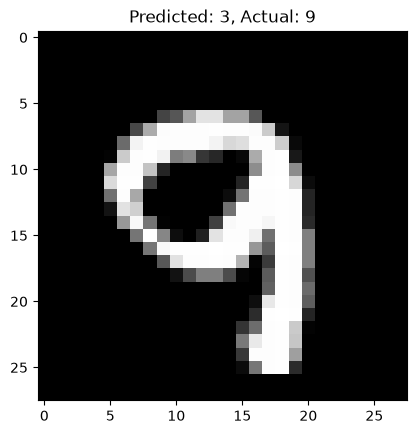

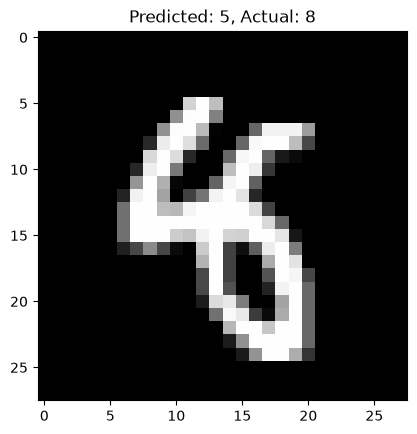

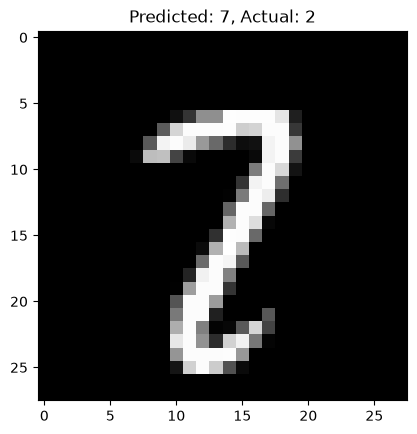

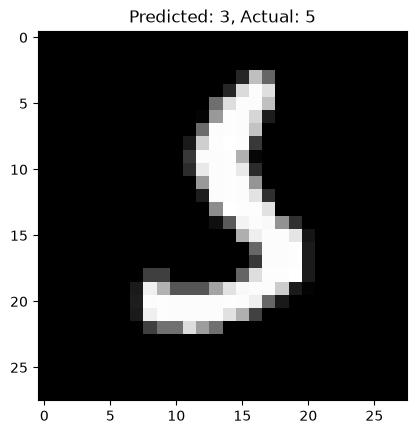

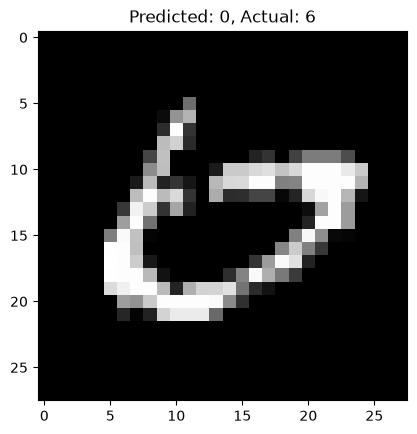

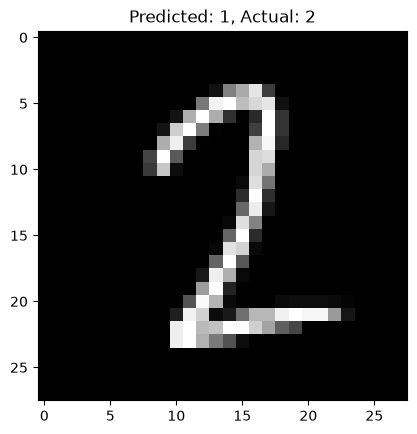

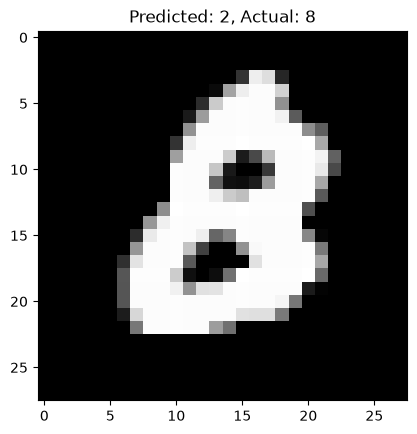

In [23]:
wrong = np.where(predicted_labels != y_test)[0]

print("Number wrong:", len(wrong))
import matplotlib.pyplot as plt

for i in range(10):
    idx = wrong[i]
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title(
        f"Predicted: {predicted_labels[idx]}, Actual: {y_test[idx]}"
    )
    plt.show()